α =     0.0001   f(α) = 1.000000
α =      0.001   f(α) = 1.000000
α =       0.01   f(α) = 1.000006
α =        0.1   f(α) = 1.000545
α =        0.5   f(α) = 1.009339
α =          1   f(α) = 1.026665
α =          2   f(α) = 1.065105
α =          3   f(α) = 1.100899
α =          4   f(α) = 1.132313
α =          5   f(α) = 1.159682
α =          7   f(α) = 1.200951
α =         10   f(α) = 1.244698
α =         15   f(α) = 1.294429
α =         20   f(α) = 1.329713
α =         25   f(α) = 1.357082
α =         30   f(α) = 1.379444
α =         50   f(α) = 1.422360
α =        100   f(α) = 1.458420
α =       1000   f(α) = 1.495537
α =      10000   f(α) = 1.499550
α =     100000   f(α) = 1.499955


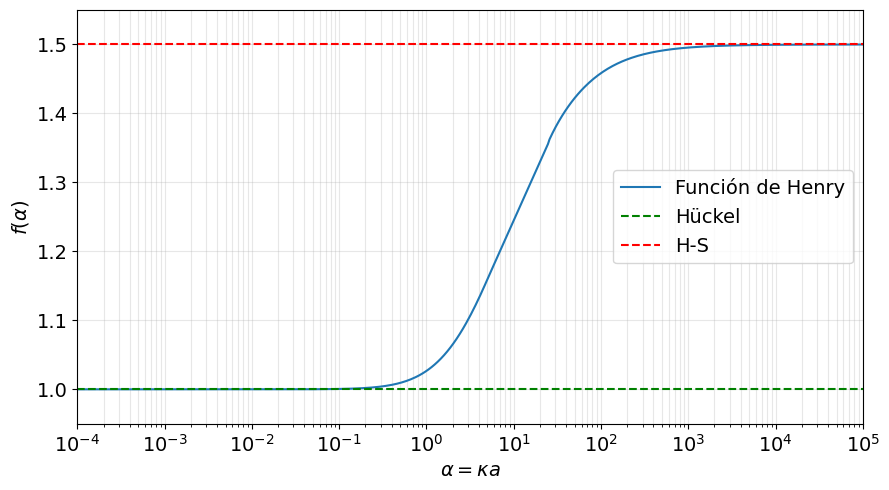

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import exp1

def henry(alpha):

    if 0 < alpha < 5:

        I = exp1(alpha)

        f = (1 + alpha**2/16 - 5*alpha**3/48
             - alpha**4/96 + alpha**5/96
             + (alpha**4/8 - alpha**6/96)
             * np.exp(alpha) * I)

    elif alpha > 25:

        f = (3/2 - 9/(2*alpha)
             + 75/(2*alpha**2) - 330/alpha**3)

    else:

        f_4 = henry(4)
        f_30 = henry(30)

        f = f_4 + (f_30 - f_4) * (
            (np.log10(alpha) - np.log10(4))
            / (np.log10(30) - np.log10(4))
        )

    return f


# Valores de alpha seleccionados apartado a y b

valores = [1e-4, 1e-3, 1e-2, 0.1, 0.5,1, 2, 3, 4, 5, 7, 10,15, 20, 25, 30, 50, 100,1000, 10000, 100000]

# Calcular y mostrar la función de Henry

for alpha in valores:
    print(f"α = {alpha:10g}   f(α) = {henry(alpha):.6f}")


# Representación gráfica

alphas = np.logspace(-4, 5, 500)
funcion = [henry(alpha) for alpha in alphas]

plt.figure(figsize=(9, 5))

plt.semilogx(alphas, funcion, label="Función de Henry")

# Tendencia de Hückel y H-S
plt.axhline(1, linestyle="--", color="green", label="Hückel")
plt.axhline(1.5, linestyle="--", color="red", label="H-S")

plt.xlabel(r"$\alpha = \kappa a$", fontsize=14)
plt.ylabel(r"$f(\alpha)$", fontsize=14)

plt.tick_params(axis="both", labelsize=14)

plt.xlim(1e-4, 1e5)
plt.ylim(0.95, 1.55)

plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()

   
  
